# 01 · Exploratory Data Analysis: Who Churns?

**Business question:** *Which bank customers are most likely to churn, what factors are associated with churn, and how can the bank use this to improve retention?*

This notebook covers the **descriptive** part of that question. It looks at how churn varies across customer characteristics before any model is built.

| Business question | Where it is answered |
|---|---|
| Q1. What percentage of customers churn? | Section 2 |
| Q2. Which customer segments have the highest churn? | Section 5 |
| Q3. Which characteristics are most strongly associated with churn? | Section 4 |
| Q4. Does customer activity affect churn? | Section 3.6 |
| Q5. Does the number of products affect retention? | Section 3.5 |
| Q6. Are older customers more likely to churn? | Section 3.3 |
| Q7. Are there meaningful geographic differences? | Section 3.1 |

> **A note on language.** Everything in this notebook is an **association**: churn rates differ between groups. It does *not* show that a characteristic *causes* churn. For example, a higher churn rate in one country could reflect the products sold there, the local competition, or how the data was collected.

## 1. Setup and data overview

In [1]:
import sys
from pathlib import Path

# Make the shared helpers in src/ importable whether the notebook is run from
# the project root or from the notebooks/ folder
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency, mannwhitneyu

from src.churn_utils import (
    COLOR_CHURN,
    COLOR_MUTED,
    COLOR_PRIMARY,
    TARGET,
    churn_rate_table,
    load_raw_data,
    plot_churn_rate,
    save_figure,
    set_plot_style,
)

set_plot_style()
df = load_raw_data()
print(f"{df.shape[0]:,} customers, {df.shape[1]} columns")
df.head()

10,000 customers, 14 columns


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


**The variables**

| Column | Meaning |
|---|---|
| `RowNumber`, `CustomerId`, `Surname` | Identifiers. Not used for analysis |
| `CreditScore` | Credit score (350–850) |
| `Geography` | Country: France, Germany or Spain |
| `Gender` | Female / Male |
| `Age` | Age in years |
| `Tenure` | Years as a customer (0–10) |
| `Balance` | Account balance |
| `NumOfProducts` | Number of bank products held (1–4) |
| `HasCrCard` | 1 if the customer has a credit card |
| `IsActiveMember` | 1 if the bank classifies the customer as active. The dataset does not define "active" |
| `EstimatedSalary` | The bank's *estimate* of the customer's salary |
| `Exited` | **Target**: 1 if the customer left the bank |

The dataset doesn't state the currency, the observation period, or how "active" is defined. These are real limitations when interpreting the results.

In [2]:
# Data quality checks: types, missing values, duplicate customers
print("Missing values per column:", df.isna().sum().sum())
print("Duplicate customer IDs:  ", df["CustomerId"].duplicated().sum())
df.describe().round(1).T

Missing values per column: 0
Duplicate customer IDs:   0


,count,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,5000.5,2886.9,1.0,2500.8,5000.5,7500.2,10000.0
CustomerId,10000.0,15690940.6,71936.2,15565701.0,15628528.2,15690738.0,15753233.8,15815690.0
CreditScore,10000.0,650.5,96.7,350.0,584.0,652.0,718.0,850.0
Age,10000.0,38.9,10.5,18.0,32.0,37.0,44.0,92.0
Tenure,10000.0,5.0,2.9,0.0,3.0,5.0,7.0,10.0
Balance,10000.0,76485.9,62397.4,0.0,0.0,97198.5,127644.2,250898.1
NumOfProducts,10000.0,1.5,0.6,1.0,1.0,1.0,2.0,4.0
HasCrCard,10000.0,0.7,0.5,0.0,0.0,1.0,1.0,1.0
IsActiveMember,10000.0,0.5,0.5,0.0,0.0,1.0,1.0,1.0
EstimatedSalary,10000.0,100090.2,57510.5,11.6,51002.1,100193.9,149388.2,199992.5


The data is complete, with no missing values and no duplicate customers. Two things stand out in the summary:
* **Balance**: the minimum *and* the 25th percentile are 0, so a large share of customers hold a zero balance (examined in Section 3.4).
* **EstimatedSalary** is spread almost uniformly between roughly 0 and 200k. That looks synthetic, so it probably carries little real signal.

## 2. Q1 – What percentage of customers churn?

Churned customers: 2,037 of 10,000 (20.4%)
Retained customers: 79.6%


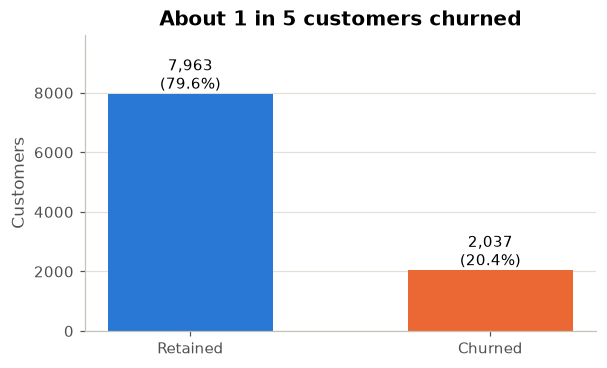

In [3]:
churn_rate = df[TARGET].mean()
print(f"Churned customers: {df[TARGET].sum():,} of {len(df):,} ({churn_rate:.1%})")
print(f"Retained customers: {(1 - churn_rate):.1%}")

fig, ax = plt.subplots(figsize=(6, 3.5))
counts = df[TARGET].value_counts().sort_index()
bars = ax.bar(["Retained", "Churned"], counts.values, color=[COLOR_PRIMARY, COLOR_CHURN], width=0.55)
for bar, n in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n, f"{n:,}\n({n / len(df):.1%})",
            ha="center", va="bottom", fontsize=10)
ax.set_ylim(0, counts.max() * 1.25)
ax.set_ylabel("Customers")
ax.set_title("About 1 in 5 customers churned")
save_figure(fig, "01_churn_overview")
plt.show()

**20.4% of customers (2,037 of 10,000) left the bank.**

This has two consequences for the rest of the project:
1. **Churn is a big business problem.** Losing one customer in five is a large share of the customer base.
2. **The classes are imbalanced (80/20).** A model that predicts "nobody churns" would already be 79.6% accurate while catching zero churners. That's why later notebooks focus on recall, precision and ROC-AUC rather than accuracy alone.

## 3. Churn across customer characteristics

Each chart shows the **churn rate within each group**. The dashed line is the overall churn rate (20.4%), and the white `n=` label shows group size, so small groups can be read with caution.

### 3.1 Q7 – Geography

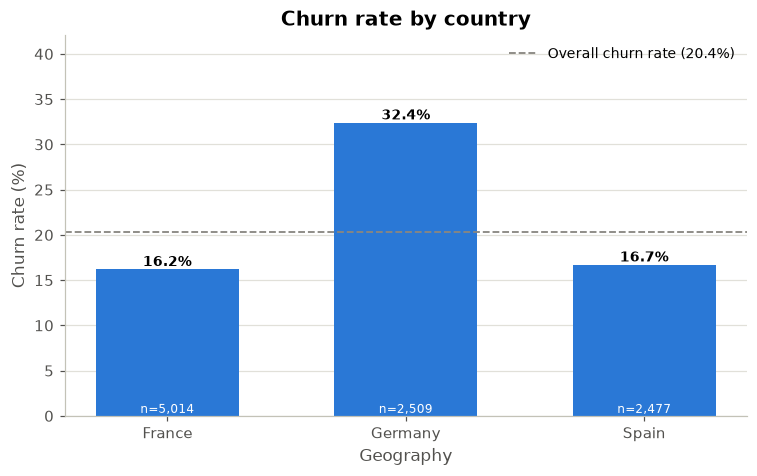

In [4]:
fig, ax = plt.subplots()
plot_churn_rate(df, "Geography", ax=ax, title="Churn rate by country")
save_figure(fig, "01_churn_by_geography")
plt.show()

**Customers in Germany churn at about twice the rate of France and Spain** (32.4% vs 16.2% and 16.7%). France and Spain are almost identical.

There's one important detail. Germany is the only country with **no zero-balance customers**, and its average balance is about twice that of France and Spain (checked below). So geography and balance are entangled: part of the "Germany effect" could be a "customers with money in the account" effect, or vice versa. The data can't separate the two. A bank would need to look into it (local competition, product mix, service levels).

In [5]:
geo_balance = df.groupby("Geography")["Balance"].agg(
    mean_balance="mean", share_zero_balance=lambda s: (s == 0).mean()
)
geo_balance.round(2)

,mean_balance,share_zero_balance
Geography,,
France,62092.64,0.48
Germany,119730.12,0.00
Spain,61818.15,0.48


### 3.2 Gender

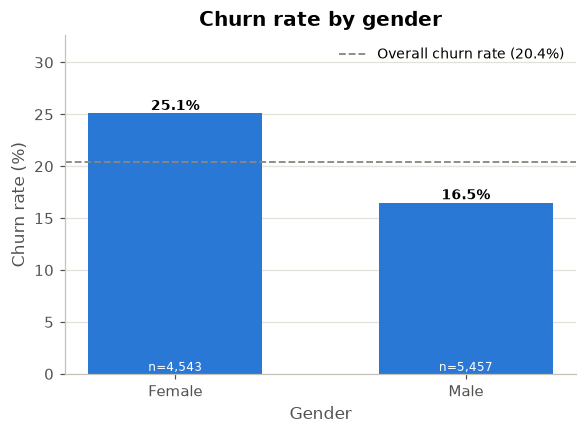

Gender,Female,Male
Geography,,
France,20.3,12.7
Germany,37.6,27.8
Spain,21.2,13.1


In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
plot_churn_rate(df, "Gender", ax=ax, title="Churn rate by gender")
plt.show()
pd.crosstab(df["Geography"], df["Gender"], values=df[TARGET], aggfunc="mean").mul(100).round(1)

**Female customers churn more often than male customers** (25.1% vs 16.5%). The gap appears in every country (table above), so it isn't explained by geography. The dataset has no information on *why*. It could relate to product fit, service experience or other unobserved factors, so this is a pattern worth investigating rather than a conclusion.

### 3.3 Q6 – Age

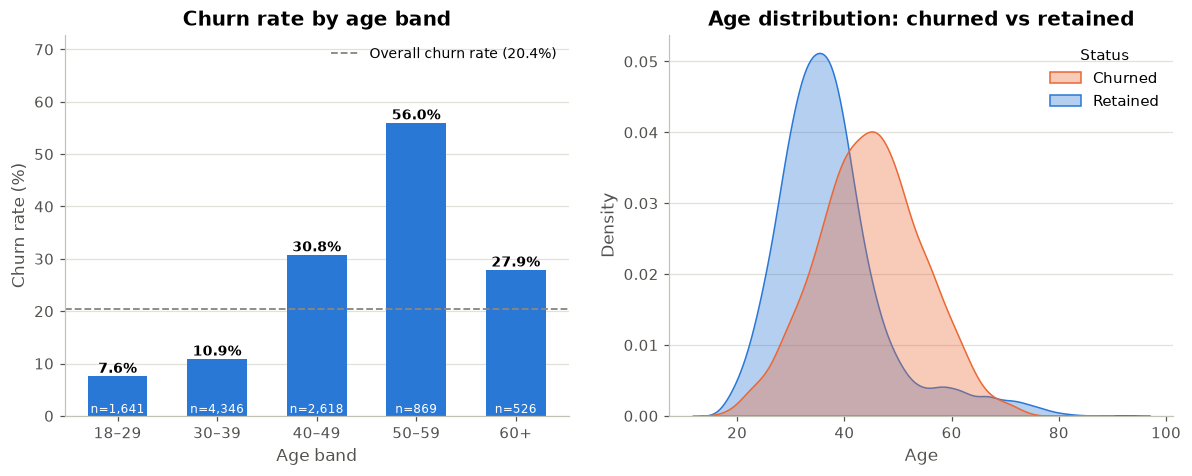

In [7]:
df["AgeBand"] = pd.cut(df["Age"], bins=[17, 29, 39, 49, 59, 92],
                       labels=["18–29", "30–39", "40–49", "50–59", "60+"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_churn_rate(df, "AgeBand", ax=axes[0], title="Churn rate by age band", xlabel="Age band")
status = df[TARGET].map({0: "Retained", 1: "Churned"})
sns.kdeplot(data=df.assign(Status=status), x="Age", hue="Status", common_norm=False, fill=True,
            alpha=0.35, palette={"Retained": COLOR_PRIMARY, "Churned": COLOR_CHURN}, ax=axes[1])
axes[1].set_title("Age distribution: churned vs retained")
axes[1].set_ylabel("Density")
save_figure(fig, "01_churn_by_age")
plt.show()

**Age shows the strongest pattern in the dataset, and it isn't a straight line.**
* Churn is low for under-40s (7.6% for 18–29, 10.9% for 30–39).
* It jumps for 40–49 (30.8%) and **peaks at 56.0% for 50–59**: more than half of these customers left.
* It falls again for 60+ (27.9%).

The median churned customer is 45, against 36 for retained customers. So yes, older customers are more likely to churn, **up to about 60**. A rule like "churn always rises with age" would be wrong. This non-linear shape is one reason tree-based models are tested later.

### 3.4 Credit score and account balance

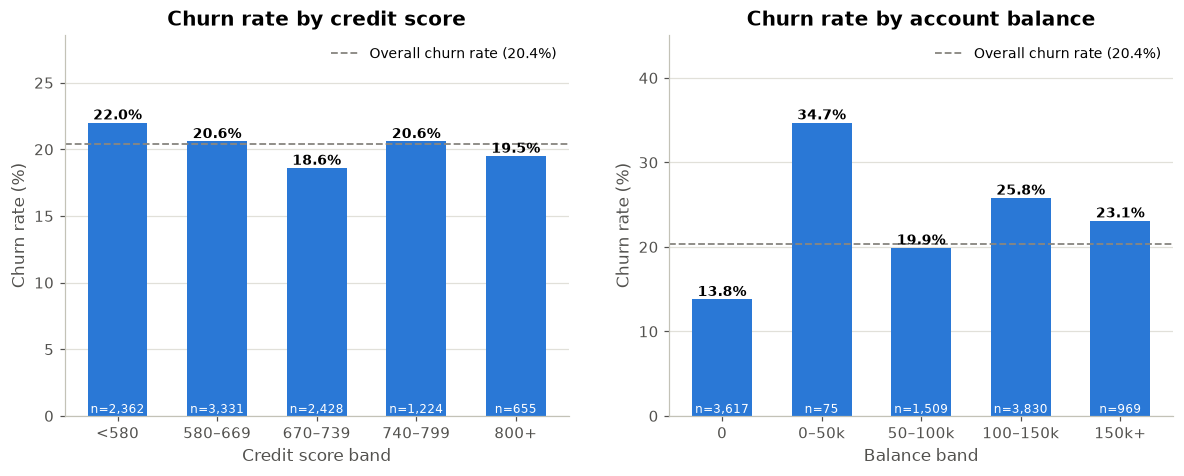

In [8]:
df["CreditBand"] = pd.cut(df["CreditScore"], bins=[349, 579, 669, 739, 799, 850],
                          labels=["<580", "580–669", "670–739", "740–799", "800+"])
df["BalanceBand"] = pd.cut(df["Balance"], bins=[-1, 0, 50_000, 100_000, 150_000, np.inf],
                           labels=["0", "0–50k", "50–100k", "100–150k", "150k+"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_churn_rate(df, "CreditBand", ax=axes[0], title="Churn rate by credit score", xlabel="Credit score band")
plot_churn_rate(df, "BalanceBand", ax=axes[1], title="Churn rate by account balance", xlabel="Balance band")
save_figure(fig, "01_churn_by_credit_balance")
plt.show()

**Credit score:** churn is almost flat across bands (18.6%–22.0%), so credit score shows **little association with churn**. One edge case stands out: all 19 customers with a score below 400 churned. That group is too small to generalise from, but it's worth flagging to the bank as a data question.

**Balance:** customers with a **zero balance churn less (13.8%)** than customers with money in the account (24.1% overall for balance > 0). The 0–50k band (34.7%) contains only 75 customers, so that rate is unreliable. This could reflect that customers with balances are more attractive to competitors, or that zero-balance accounts are dormant rather than "at risk". The data can't distinguish these. As noted above, the pattern overlaps with geography, but it still holds *within* France and Spain:

In [9]:
df.assign(HasBalance=df["Balance"] > 0).pivot_table(
    index="Geography", columns="HasBalance", values=TARGET, aggfunc="mean"
).mul(100).round(1)

HasBalance,False,True
Geography,,
France,13.9,18.2
Germany,NaN,32.4
Spain,13.6,19.6


### 3.5 Q5 – Number of products

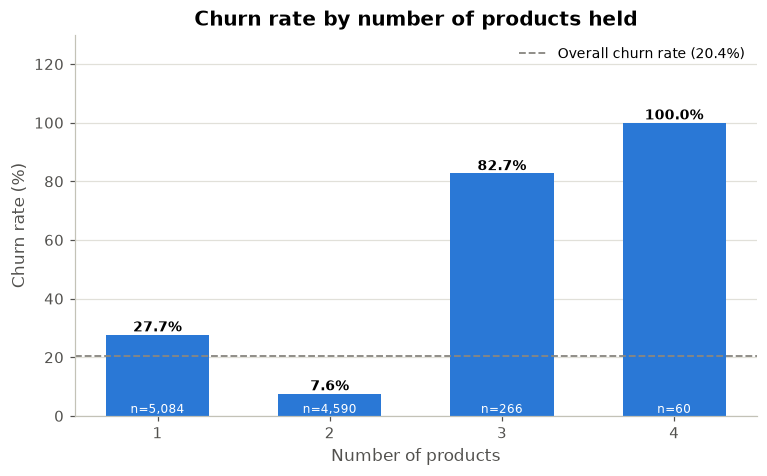

In [10]:
fig, ax = plt.subplots()
plot_churn_rate(df, "NumOfProducts", ax=ax, title="Churn rate by number of products held",
                xlabel="Number of products")
save_figure(fig, "01_churn_by_products")
plt.show()

**Number of products is strongly associated with churn, and again the relationship is not linear:**
* **2 products → lowest churn (7.6%)**
* 1 product → 27.7%
* 3 products → 82.7% and 4 products → 100%. These are small groups (266 and 60 customers), but the rates are extreme.

So "more products = more loyal" holds only from 1 to 2 products. The 3–4 product group is a red flag. It might reflect unsuitable products being bundled onto customers, or a quirk of how the dataset was built. The bank should investigate before assuming cross-selling always helps.

Note that the *linear* correlation between `NumOfProducts` and churn is only −0.05 (Section 4). It hides this strong U-shaped pattern, which is why we use group churn rates rather than relying on correlation alone.

### 3.6 Q4 – Active membership and credit card ownership

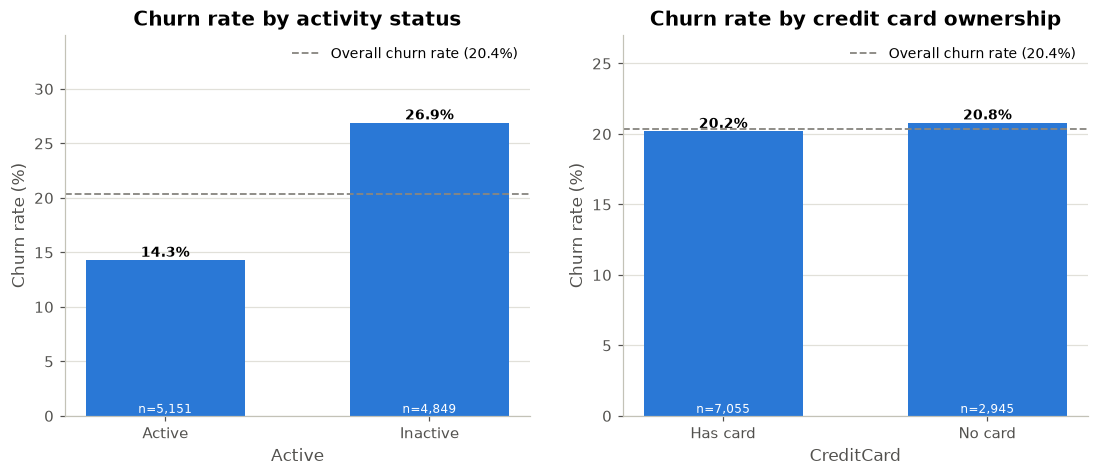

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_churn_rate(df.assign(Active=df["IsActiveMember"].map({0: "Inactive", 1: "Active"})),
                "Active", ax=axes[0], title="Churn rate by activity status", xlabel="")
plot_churn_rate(df.assign(CreditCard=df["HasCrCard"].map({0: "No card", 1: "Has card"})),
                "CreditCard", ax=axes[1], title="Churn rate by credit card ownership", xlabel="")
save_figure(fig, "01_churn_by_activity")
plt.show()

**Activity matters:** inactive customers churn at **26.9%**, almost twice the **14.3%** of active customers. That makes activity one of the most actionable signals, because engagement is something the bank can influence. Whether *increasing* activity would *reduce* churn is a causal question this data can't answer, though; it would need a controlled experiment.

**Credit card ownership shows no meaningful difference** (20.8% vs 20.2%).

### 3.7 Estimated salary and tenure

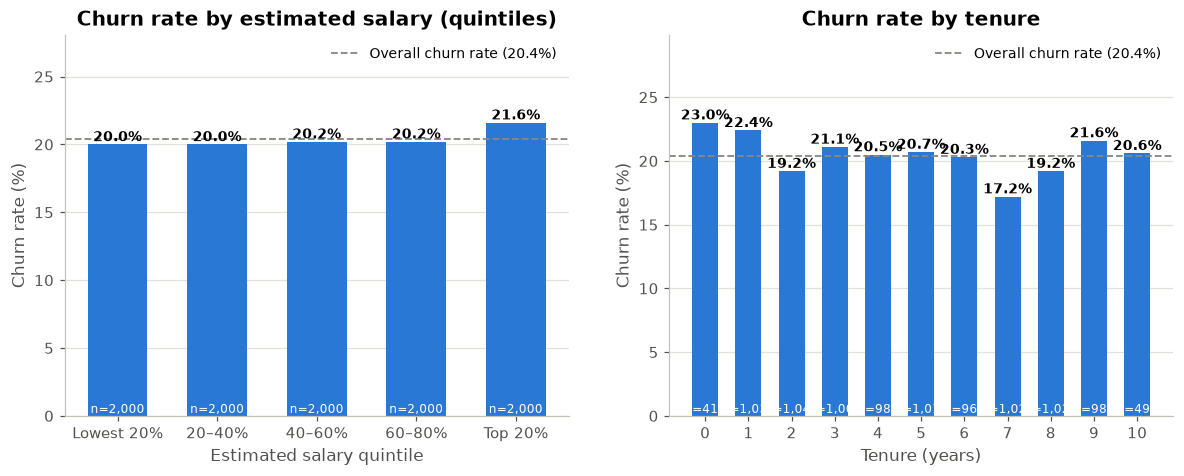

In [12]:
df["SalaryBand"] = pd.qcut(df["EstimatedSalary"], q=5,
                           labels=["Lowest 20%", "20–40%", "40–60%", "60–80%", "Top 20%"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_churn_rate(df, "SalaryBand", ax=axes[0], title="Churn rate by estimated salary (quintiles)",
                xlabel="Estimated salary quintile")
plot_churn_rate(df, "Tenure", ax=axes[1], title="Churn rate by tenure", xlabel="Tenure (years)")
save_figure(fig, "01_churn_by_salary_tenure")
plt.show()

**Neither estimated salary nor tenure shows a meaningful pattern.**
* Churn stays between 20.0% and 21.6% across all salary quintiles.
* Churn ranges from 17.2% to 23.0% across tenure years, with no consistent trend. Long-standing customers are not noticeably more loyal in this data.

This is a useful *negative* finding: a retention strategy based on salary or tenure alone would not target the right customers.

## 4. Q3 – Which characteristics are most strongly associated with churn?

To rank the variables on a common scale we use **Cramér's V**, a 0–1 measure of association between two categorical variables (numeric variables are grouped into the bands used above). A chi-square test checks whether each difference is larger than random variation would produce. A small *p*-value (< 0.05) suggests the difference is unlikely to be chance.

We also show the plain (Pearson) correlation with churn, to illustrate how a *linear* measure can miss non-linear patterns.

In [13]:
def cramers_v(x, y):
    """Strength of association between two categorical variables (0 = none, 1 = perfect)."""
    table = pd.crosstab(x, y)
    chi2, p_value, _, _ = chi2_contingency(table)
    n = table.to_numpy().sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1))), p_value


grouped_variables = {
    "NumOfProducts": "NumOfProducts", "Age": "AgeBand", "Geography": "Geography",
    "IsActiveMember": "IsActiveMember", "Balance": "BalanceBand", "Gender": "Gender",
    "Tenure": "Tenure", "CreditScore": "CreditBand", "EstimatedSalary": "SalaryBand",
    "HasCrCard": "HasCrCard",
}
rows = []
for variable, grouped_column in grouped_variables.items():
    v, p = cramers_v(df[grouped_column], df[TARGET])
    is_numeric = pd.api.types.is_numeric_dtype(df[variable])
    pearson = df[variable].corr(df[TARGET]) if is_numeric else np.nan
    rows.append({"Variable": variable, "Cramér's V": v, "p-value": p, "Pearson r": pearson})

association = pd.DataFrame(rows).sort_values("Cramér's V", ascending=False).reset_index(drop=True)
association["Significant (p<0.05)"] = np.where(association["p-value"] < 0.05, "Yes", "No")
association.style.format({"Cramér's V": "{:.3f}", "p-value": "{:.1e}", "Pearson r": "{:.2f}"},
                         na_rep="– (categorical)")

,Variable,Cramér's V,p-value,Pearson r,Significant (p<0.05)
0,NumOfProducts,0.388,0.0e+00,-0.05,Yes
1,Age,0.358,1.9e-276,0.29,Yes
2,Geography,0.174,3.8e-66,– (categorical),Yes
3,IsActiveMember,0.156,8.8e-55,-0.16,Yes
4,Balance,0.134,1.5e-37,0.12,Yes
5,Gender,0.106,2.2e-26,– (categorical),Yes
6,Tenure,0.037,1.8e-01,-0.01,No
7,CreditScore,0.030,6.3e-02,-0.03,No
8,EstimatedSalary,0.015,6.9e-01,0.01,No
9,HasCrCard,0.007,4.9e-01,-0.01,No


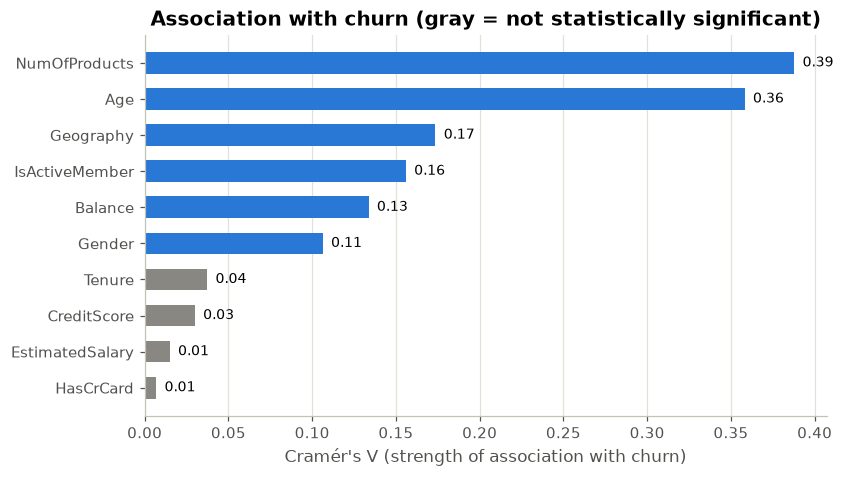

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_data = association.sort_values("Cramér's V")
colors = [COLOR_PRIMARY if s == "Yes" else COLOR_MUTED for s in plot_data["Significant (p<0.05)"]]
ax.barh(plot_data["Variable"], plot_data["Cramér's V"], color=colors, height=0.6)
for y, v in enumerate(plot_data["Cramér's V"]):
    ax.text(v + 0.005, y, f"{v:.2f}", va="center", fontsize=9)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Cramér's V (strength of association with churn)")
ax.set_title("Association with churn (gray = not statistically significant)")
save_figure(fig, "01_association_ranking")
plt.show()

**Ranking of associations with churn:**
1. **Number of products** (V ≈ 0.39) and **age** (V ≈ 0.36) are by far the strongest.
2. **Geography** (0.17), **active membership** (0.16), **balance** (0.13) and **gender** (0.11) form a clear second tier.
3. **Tenure, credit score, estimated salary and credit card ownership** are weak and not statistically significant at the 5% level.

Notice that `NumOfProducts` has a near-zero Pearson correlation (−0.05) but the *strongest* Cramér's V. Its relationship with churn is U-shaped, and a linear measure misses it entirely.

In [15]:
# For completeness: how numeric variables differ between churned and retained customers
numeric_comparison = []
for column in ["Age", "Balance", "CreditScore", "EstimatedSalary", "Tenure"]:
    churned, retained = df.loc[df[TARGET] == 1, column], df.loc[df[TARGET] == 0, column]
    numeric_comparison.append({
        "Variable": column,
        "Median (churned)": churned.median(),
        "Median (retained)": retained.median(),
        "Mann-Whitney p-value": mannwhitneyu(churned, retained).pvalue,
    })
pd.DataFrame(numeric_comparison).style.format(
    {"Median (churned)": "{:,.0f}", "Median (retained)": "{:,.0f}", "Mann-Whitney p-value": "{:.1e}"}
)

,Variable,Median (churned),Median (retained),Mann-Whitney p-value
0,Age,45,36,3.2e-230
1,Balance,"109,349","92,073",1.1e-28
2,CreditScore,646,653,2.0e-02
3,EstimatedSalary,"102,461","99,645",2.3e-01
4,Tenure,5,5,1.6e-01


The Mann-Whitney test compares the full distributions of churned and retained customers. Age and Balance differ strongly. Credit score differs only slightly (medians 646 vs 653: statistically detectable with 10,000 customers but small in practical terms). Salary and tenure show no difference.

## 5. Q2 – Which customer segments have the highest churn?

Single variables only tell part of the story. Below we combine pairs of the strongest variables and list the **highest-churn segments with at least 100 customers**, so the rates are reasonably reliable.

In [16]:
df["Activity"] = df["IsActiveMember"].map({0: "Inactive", 1: "Active"})
df["Products"] = df["NumOfProducts"].astype(str) + " product(s)"

segment_pairs = [("AgeBand", "Activity"), ("Geography", "Activity"), ("Geography", "Gender"),
                 ("Products", "Activity"), ("AgeBand", "Geography"), ("AgeBand", "Gender")]
segments = []
for a, b in segment_pairs:
    grouped = df.groupby([a, b], observed=True)[TARGET].agg(customers="size", churn_rate="mean").reset_index()
    grouped["Segment"] = grouped[a].astype(str) + " · " + grouped[b].astype(str)
    segments.append(grouped[["Segment", "customers", "churn_rate"]])

segments = (pd.concat(segments).query("customers >= 100").drop_duplicates("Segment")
            .sort_values("churn_rate", ascending=False).reset_index(drop=True))
segments["churn_rate"] = (segments["churn_rate"] * 100).round(1)
segments.head(10)

,Segment,customers,churn_rate
0,3 product(s) · Inactive,153,88.2
1,60+ · Inactive,111,85.6
2,50–59 · Inactive,373,81.2
3,3 product(s) · Active,113,75.2
4,50–59 · Germany,277,70.0
5,50–59 · Female,421,62.9
6,50–59 · France,382,51.6
7,50–59 · Male,448,49.6
8,50–59 · Spain,210,45.7
9,40–49 · Germany,740,45.1


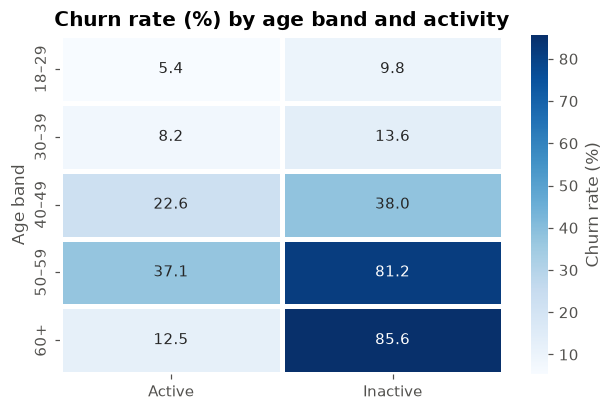

In [17]:
age_activity = df.pivot_table(index="AgeBand", columns="Activity", values=TARGET,
                              aggfunc="mean", observed=True)[["Active", "Inactive"]] * 100
fig, ax = plt.subplots(figsize=(6.5, 4))
sns.heatmap(age_activity, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "Churn rate (%)"},
            linewidths=2, linecolor="white", ax=ax)
ax.set_title("Churn rate (%) by age band and activity")
ax.set_xlabel(""); ax.set_ylabel("Age band")
save_figure(fig, "01_age_activity_heatmap")
plt.show()

**The highest-risk segments combine *older age*, *inactivity* and *3+ products*:**
* **Inactive customers with 3 products** have the highest churn of any segment (88.2%, 153 customers). Even *active* 3-product customers churn at 75.2%.
* **Inactive customers aged 60+** churned at 85.6% (111 customers), and **inactive 50–59** at 81.2% (373 customers).
* Being **active** goes with much lower churn *within the same age group*. For 60+, active customers churned at only 12.5% versus 85.6% for inactive ones.
* **Customers aged 50–59 in Germany** churned at 70.0%, and **inactive customers in Germany** at 41.1%, the highest of any country/activity combination.

This interaction between age and activity is exactly the kind of pattern that a simple single-variable rule misses, and that a machine-learning model can pick up.

## 6. Summary of EDA findings

| # | Business question | Answer from the data |
|---|---|---|
| Q1 | What percentage of customers churn? | **20.4%** (2,037 of 10,000). Classes are imbalanced 80/20 |
| Q2 | Which segments churn most? | **Older (50+) inactive customers** (81–86%), customers with **3–4 products** (83–100%), **inactive customers in Germany** (41%) |
| Q3 | Strongest associations? | **Number of products** and **age**, then geography, activity, balance and gender. Credit score, salary, tenure and credit-card ownership show little or no association |
| Q4 | Does activity matter? | Yes. Inactive customers churn at **26.9% vs 14.3%** for active ones, and the gap is largest among older customers |
| Q5 | Do products matter? | Yes, non-linearly. **2 products = 7.6%** churn (lowest); 1 product = 27.7%; 3–4 products = 83–100% (small groups) |
| Q6 | Are older customers more likely to churn? | Yes, up to about 60. Churn peaks at **56% for ages 50–59** and drops to 28% for 60+ |
| Q7 | Geographic differences? | Yes. **Germany 32.4%** vs ~16% in France and Spain, partly entangled with Germany's higher balances |

**Limitations:** these are associations in a single snapshot of data. They don't show what *causes* churn, and the dataset lacks important context (time period, currency, product types, complaints, interactions with the bank).

**Next:** notebook 02 prepares the data for modelling, and notebook 03 tests whether these patterns can be used to *predict* which customers will churn.